# 🔍 Uczenie nienadzorowane - grupowanie danych

**Zajęcia wspólne (~60 min)** · praca własna: notatnik `7b`

Do tej pory robiliśmy **uczenie nadzorowane**: dane miały etykietę (np. `exam_score`), a model uczył się ją przewidywać. Dziś robimy coś innego:

> **Uczenie nienadzorowane** = dane **nie mają etykiet**. Model sam ma znaleźć w nich **ukrytą strukturę** - grupy podobnych przykładów.

### Plan na dziś
1. Po co konieczna jest **standaryzacja** danych?
2. **k-średnich (k-means)** - jak maszyna grupuje dane bez etykiet
3. **Ile grup wybrać?** - metoda łokcia
4. **Interpretacja** - co to właściwie za grupy?
5. **Wizualizacja** grup w 2D (PCA)

A na koniec sprawdzimy, czy taki podział jest w ogóle do czegokolwiek przydatny.

Przykład przewodni: mamy dane o nawykach uczniów (godziny nauki, sen, social media...) i chcemy sami odkryć **profile uczniów** - nikt nam z góry nie mówi, jakie one są.

## Dane

In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv("2_student_habits_performance.csv")

cechy = ["study_hours_per_day", "sleep_hours", "social_media_hours",
         "attendance_percentage", "exercise_frequency"]

print("Wymiary danych:", df.shape)
print("Braki w cechach:", df[cechy].isna().sum().sum())
df[cechy].head()

Wymiary danych: (1000, 16)
Braki w cechach: 0


,study_hours_per_day,sleep_hours,social_media_hours,attendance_percentage,exercise_frequency
0,0.0,8.0,1.2,85.0,6
1,6.9,4.6,2.8,97.3,6
2,1.4,8.0,3.1,94.8,1
3,1.0,9.2,3.9,71.0,4
4,5.0,4.9,4.4,90.9,3


In [3]:
# Podstawowe statystyki — zwróć uwagę na RÓŻNE SKALE kolumn
df[cechy].describe().round(1)

,study_hours_per_day,sleep_hours,social_media_hours,attendance_percentage,exercise_frequency
count,1000.0,1000.0,1000.0,1000.0,1000.0
mean,3.6,6.5,2.5,84.1,3.0
std,1.5,1.2,1.2,9.4,2.0
min,0.0,3.2,0.0,56.0,0.0
25%,2.6,5.6,1.7,78.0,1.0
50%,3.5,6.5,2.5,84.4,3.0
75%,4.5,7.3,3.3,91.0,5.0
max,8.3,10.0,7.2,100.0,6.0


## 1. Dlaczego standaryzacja?

Popatrz na `describe()` powyżej - cechy są w kompletnie różnych jednostkach:

| cecha | zakres | jednostka |
|---|---|---|
| `attendance_percentage` | 56 - 100 | procenty |
| `sleep_hours` | 3,2 - 10,0 | godziny |
| `study_hours_per_day` | 0,0 - 8,3 | godziny |
| `social_media_hours` | 0,0 - 7,2 | godziny |
| `exercise_frequency` | 0 - 6 | razy w tygodniu |

k-means mierzy **odległości** między punktami, a odległość liczy z surowych liczb.
Zmiana frekwencji o 10 punktów procentowych "waży" w niej tyle, co zmiana snu o 10 godzin -
mimo że jedno nie jest równoważne drugiemu.

Bez standaryzacji k-means podzieliłby więc uczniów niemal wyłącznie **po frekwencji**, a nauka, sen
i sport nie miałyby prawie żadnego wpływu na wynik.

**Standaryzacja** sprowadza każdą cechę do tej samej skali:

$$x_{std} = \frac{x - \text{średnia}}{\text{odchylenie standardowe}}$$

Po niej każda cecha ma średnią 0 i odchylenie 1, więc wszystkie ważą tyle samo.
To ta sama `StandardScaler`, którą wkładaliśmy do `Pipeline` w notatnikach 4-6 -
tam przed SVM i regresją logistyczną, tu przed k-means. Powód jest identyczny:
**metody oparte na odległościach są wrażliwe na skalę**.

> A co by się stało, gdybyśmy standaryzację pominęli? Sprawdzicie to sami w notatniku `7b`.

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(df[cechy])   # tylko wybrane cechy

print("Kształt X:", X.shape)                                       
print("Średnie kolumn po standaryzacji ~", X.mean(axis=0).round(2))  
print("Odchylenia kolumn po standaryzacji ~", X.std(axis=0).round(2)) 

# Scaler zapamiętał oryginalne średnie i odchylenia kolumn
print("\nśrednie przed standaryzacją:  ", scaler.mean_.round(2))
print("odchylenia przed standaryzacją:", scaler.scale_.round(2))

Kształt X: (1000, 5)
Średnie kolumn po standaryzacji ~ [-0. -0. -0.  0.  0.]
Odchylenia kolumn po standaryzacji ~ [1. 1. 1. 1. 1.]

średnie przed standaryzacją:   [ 3.55  6.47  2.51 84.13  3.04]
odchylenia przed standaryzacją: [1.47 1.23 1.17 9.39 2.02]


### Zanim zaczniemy grupować - czy jest czego szukać?

Grupa to zestaw uczniów podobnych pod wieloma względami naraz. Żeby takie zestawy
powstały, cechy muszą być ze sobą **powiązane**. Sprawdźmy to przed grupowaniem.

In [20]:
df[cechy].corr().round(2)

,study_hours_per_day,sleep_hours,social_media_hours,attendance_percentage,exercise_frequency
study_hours_per_day,1.00,-0.03,0.02,0.03,-0.03
sleep_hours,-0.03,1.00,0.02,0.01,0.02
social_media_hours,0.02,0.02,1.00,0.04,-0.04
attendance_percentage,0.03,0.01,0.04,1.00,-0.01
exercise_frequency,-0.03,0.02,-0.04,-0.01,1.00


Wszystkie wartości poza przekątną mieszczą się między -0,04 a +0,04, czyli praktycznie zero.
To, ile ktoś śpi, nie mówi nic o tym, ile się uczy. Cechy są niezależne - a to znaczy,
że chmura punktów jest równomierna i naturalnych grup raczej nie znajdziemy.

Sprawdźmy, czy k-means to potwierdzi.

## 2. k-means - grupowanie bez etykiet

Algorytm **k-średnich** szuka `k` grup. Działa tak:

1. Wybiera `k` punktów-środków (centroidów) - w `scikit-learn` nie całkiem losowo,
   a metodą `k-means++`, która stara się rozstawić je daleko od siebie.
2. **Przypisuje** każdy przykład do najbliższego środka.
3. **Przesuwa** każdy środek na średnią swoich przykładów.
4. Powtarza kroki 2-3, aż środki przestaną się ruszać (albo do `max_iter`, domyślnie 300 obrotów).

Czego ten algorytm właściwie szuka? Chce, żeby punkty leżały **blisko środka swojej grupy**.
Mierzy to jedną liczbą - sumą kwadratów odległości każdego punktu od środka jego grupy:

$$\mathcal{L} = \sum_{j=1}^{k} \sum_{x \in S_j} \lVert x - \mu_j \rVert^2$$

gdzie $S_j$ to j-ta grupa, a $\mu_j$ jej środek. Kroki 2 i 3 nigdy tej liczby nie zwiększają,
dlatego algorytm zawsze się w końcu zatrzymuje. W `scikit-learn` nazywa się ona `inertia_`
i wrócimy do niej w sekcji 3.

Dwie rzeczy, o których warto pamiętać:

- Punkt 1 zawiera **losowość**, więc dwa uruchomienia mogą dać różne grupy. Dlatego podajemy
  `n_init=10`: algorytm przechodzi całość 10 razy z różnych startów i zwraca najlepszy wynik
  (ten z najmniejszą `inertia_`). A `random_state=0` sprawia, że u każdego wyjdzie to samo.
- k-means **zawsze** zwróci `k` grup. Nawet gdy w danych żadnych grup nie ma - wtedy po prostu
  pokroi chmurę punktów na `k` kawałków. 
  
Na start wybierzmy `k = 4` i zobaczmy, co wyjdzie.

In [5]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, n_init=10, random_state=0)
grupy = kmeans.fit_predict(X)     # numer grupy (0,1,2,3) dla każdego ucznia

df["grupa"] = grupy               # dopisujemy wynik do tabeli
df[cechy + ["grupa"]].head()      # pokazujemy tylko to, co weszło do modelu, i wynik

,study_hours_per_day,sleep_hours,social_media_hours,attendance_percentage,exercise_frequency,grupa
0,0.0,8.0,1.2,85.0,6,2
1,6.9,4.6,2.8,97.3,6,3
2,1.4,8.0,3.1,94.8,1,1
3,1.0,9.2,3.9,71.0,4,2
4,5.0,4.9,4.4,90.9,3,3


In [6]:
# Ilu uczniów trafiło do każdej grupy?
df["grupa"].value_counts().sort_index()

grupa
0    269
1    228
2    258
3    245
Name: count, dtype: int64

## 3. Ile powinno być grup? - metoda łokcia

`k = 4` wzięliśmy tak po prostu. Pytanie: jak dobrać `k` z sensem?

Dla każdego `k` liczymy **inercję** - to dokładnie ta suma kwadratów odległości,
którą algorytm minimalizuje, dostępna jako `kmeans.inertia_`.
Im mniejsza, tym ciaśniejsze grupy.

Jest jednak haczyk: **inercja zawsze maleje, gdy zwiększamy `k`**. Przy `k` równym
liczbie uczniów każdy byłby osobną grupą i inercja wyniosłaby dokładnie zero.
Nie możemy więc po prostu wybrać `k` z najmniejszą inercją - zawsze wygrywałoby
największe `k`.

Dlatego patrzymy nie na samą wartość, tylko na **tempo spadku**. Jeśli w danych
naprawdę siedzą cztery grupy, to przejście z 3 na 4 mocno poprawia wynik,
a z 4 na 5 - już prawie wcale. Wykres załamuje się wtedy jak **łokieć**
i to miejsce wskazuje dobre `k`.

Sprawdźmy, czy nasz wykres taki łokieć ma. Policzymy też, o ile procent
spada inercja przy każdym kroku - żeby nie trzeba było zgadywać z oka.

  k | inercja | spadek
  1 |    5000 |       
  2 |    4226 |  15.5%
  3 |    3779 |  10.6%
  4 |    3422 |   9.5%
  5 |    3112 |   9.0%
  6 |    2861 |   8.1%
  7 |    2692 |   5.9%


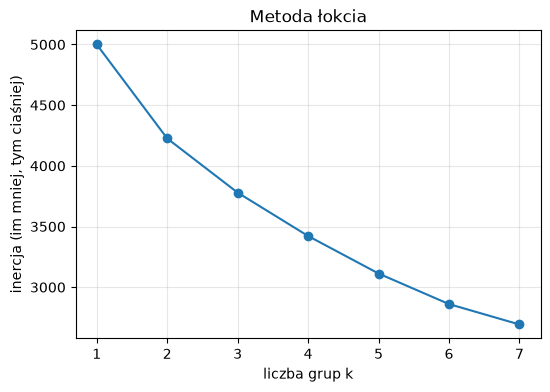

In [ ]:
inercje = []
zakres_k = range(1, 8)
for k in zakres_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inercje.append(km.inertia_)
    

import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(list(zakres_k), inercje, "o-")
plt.xlabel("liczba grup k")
plt.ylabel("inercja (im mniej, tym ciaśniej)")
plt.title("Metoda łokcia")
plt.grid(alpha=0.3)
plt.show()

**Jak czytać ten wykres:** szukamy miejsca, w którym krzywa ze stromej robi się płaska -
"łokcia". Tutaj takiego miejsca **nie ma**. Krzywa opada gładko, bez załamania:

| przejście | spadek inercji |
|---|---|
| 1 → 2 | 15,5% |
| 2 → 3 | 10,6% |
| 3 → 4 | 9,5% |
| 4 → 5 | 9,0% |
| 5 → 6 | 8,1% |
| 6 → 7 | 5,9% |

Każda kolejna grupa poprawia wynik o podobną wartość. Nie ma takiego `k`, po którym
zysk nagle znika - a dokładnie tego szuka metoda łokcia.

**Uwaga:** każda opadająca krzywa wygląda tak, jakby gdzieś się zaginała.
Gdyby pięć osób wskazało tutaj łokieć, dostalibyśmy pięć różnych odpowiedzi -
i każda brzmiałaby przekonująco. Jeśli nie widać wyraźnego urwiska, to go nie ma.

**Co to oznacza?** W tych danych nie ma naturalnych grup uczniów. Jest jedna wielka
chmura, którą k-means kroi na tyle kawałków, ile mu każemy. To zupełnie normalna
sytuacja przy prawdziwych danych - nie jest to błąd ani nasz, ani algorytmu.

**To jak wybrać `k`?** Skoro dane nie podpowiadają, decyduje **cel**. Chcemy podziału,
który da się opisać i do czegoś użyć: przy `k = 2` profile są zbyt ogólne, przy `k = 6-7`
zaczynają się powtarzać. Zostajemy przy **`k = 4`** - ale ze świadomością, że to nasza
decyzja, a nie odkrycie w danych.

Czy taki podział jest w ogóle do czegokolwiek przydatny?

## 4. Co to za grupy? - interpretacja

Numer grupy (0,1,2,3) sam w sobie nic nie znaczy. Żeby grupy **zrozumieć**, patrzymy na **średnie cech** w każdej z nich i nadajemy im nazwy.

In [11]:
# Średnie wartości cech w każdej grupie
df[cechy + ["grupa"]].groupby("grupa").mean().round(1)

,study_hours_per_day,sleep_hours,social_media_hours,attendance_percentage,exercise_frequency
grupa,,,,,
0,3.5,6.3,2.0,79.3,1.0
1,3.8,7.1,3.4,92.6,2.2
2,2.4,6.9,2.2,81.7,4.6
3,4.6,5.6,2.5,84.2,4.4


**Odczytanie tabeli.** Numer grupy sam w sobie nic nie znaczy - to tylko etykieta.
Żeby grupy zrozumieć, porównajmy je ze średnią całego zbioru: nauka 3,6 h, sen 6,5 h,
social media 2,5 h, frekwencja 84%, ruch 3 razy w tygodniu.

- **Grupa 3** - najwięcej nauki (4,6 h) i najmniej snu (5,6 h), do tego dużo ruchu → *„Zapracowani"*
- **Grupa 2** - najmniej nauki (2,4 h), za to najwięcej ruchu (4,6) → *„Sport zamiast nauki"*
- **Grupa 1** - najwyższa frekwencja (92,6%) i najlepszy sen (7,1 h), ale mało ruchu → *„Systematyczni"*
- **Grupa 0** - prawie nie ćwiczą (1,0), najniższa frekwencja (79,3%), reszta blisko średniej → *„Wycofani"*

**Niespodzianka:** grupa z **największą** ilością social mediów (grupa 1) ma jednocześnie
**najlepszą** frekwencję i **najlepszy** sen. Stereotypowy „rozkojarzony uczeń, który siedzi
w social mediach, nie śpi i nie chodzi na zajęcia" w tych danych nie istnieje.
Dane nie potwierdziły historii, którą przynieśliśmy ze sobą - i to jest zupełnie normalne.

**Czy to są typy uczniów?** Nie. W sekcji 3 zobaczyliśmy, że naturalnych grup tutaj nie ma,
a różnice między grupami są niewielkie: nauka waha się od 2,4 do 4,6 godziny, podczas gdy
w całym zbiorze rozciąga się od 0 do 8,3. To nie są cztery gatunki uczniów, tylko cztery
**obszary jednej chmury**, którym nadaliśmy nazwy, żeby dało się o nich rozmawiać.

To wcale nie czyni ich bezużytecznymi - dokładnie tak działa segmentacja klientów w firmach.
Pytanie brzmi: czy te cztery obszary różnią się czymś, na czym nam zależy?

## 5. Zobaczmy grupy na obrazku (PCA → 2D)

Dane są 5-wymiarowe, więc nie da się ich wprost narysować. **PCA** ściska 5 cech do 2 tak,
żeby zachować jak najwięcej zmienności - a potem kolorujemy punkty według grupy.

Zanim uruchomisz komórkę: jak myślisz, co zobaczymy? Cztery wyraźne wyspy punktów,
czy jedną chmurę pokrojoną na kawałki?

Pamiętaj też, że PCA to **kompresja stratna** - z 5 wymiarów robi 2, więc część informacji
przepada. Wykres powie nam, ile dokładnie udało się zachować.

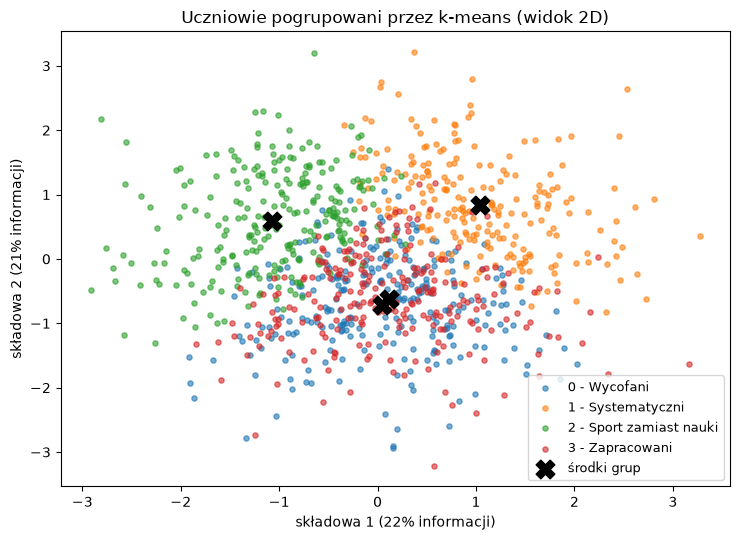

Na obrazku widać tylko 42% informacji z 5 cech.


In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
wsp_2d = pca.fit_transform(X)                        # dane w 2 wymiarach
srodki_2d = pca.transform(kmeans.cluster_centers_)   # środki grup w tym samym układzie

nazwy = {0: "Wycofani", 1: "Systematyczni", 2: "Sport zamiast nauki", 3: "Zapracowani"}

plt.figure(figsize=(7.5, 5.5))
for g, nazwa in nazwy.items():
    maska = df["grupa"] == g
    plt.scatter(wsp_2d[maska, 0], wsp_2d[maska, 1], s=14, alpha=0.6, label=f"{g} - {nazwa}")
plt.scatter(srodki_2d[:, 0], srodki_2d[:, 1], c="black", marker="X", s=180, label="środki grup")

plt.xlabel(f"składowa 1 ({pca.explained_variance_ratio_[0]*100:.0f}% informacji)")
plt.ylabel(f"składowa 2 ({pca.explained_variance_ratio_[1]*100:.0f}% informacji)")
plt.title("Uczniowie pogrupowani przez k-means (widok 2D)")
plt.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.show()

print(f"Na obrazku widać tylko {pca.explained_variance_ratio_.sum()*100:.0f}% informacji z 5 cech.")

**Co widać:** jedna chmura punktów pokrojona na kawałki - dokładnie to, co podejrzewaliśmy wcześniej. Gdyby w danych istniały prawdziwe grupy, zobaczylibyśmy oddzielone wyspy.

**Uwaga na pułapkę odwrotną.** Środki grup 0 i 3 wypadły niemal w tym samym miejscu -
sugeruje to, że możemy uznać je za jedną grupę. Ale w pełnej, 5-wymiarowej przestrzeni
dzieli je odległość 2,01, czyli tyle samo, co każdą inną parę. Płaski rzut zachował
z niej zaledwie **5%**.

Te dwie grupy różnią się głównie snem i ruchem, a akurat te kierunki PCA w dużej mierze
odrzuciło - musiało, skoro z 5 wymiarów zostawia 2. Wniosek praktyczny: na wykresie 2D
wolno sprawdzać, czy coś się **rozdziela**, ale nigdy nie wolno z niego wnioskować,
że coś się **nie rozdziela**.

### 5a. Czy dwie składowe to dużo, czy mało?

Na wykresie powyżej widzieliśmy tylko dwie pierwsze składowe. Ale PCA liczy ich tyle,
ile mamy cech - u nas pięć. Sprawdźmy, jak informacja rozkłada się między wszystkie.

Jeśli dane mają wyraźną strukturę, pierwsze składowe zagarniają większą część informacji,
a resztę można odrzucić prawie bez straty. Jeśli nie - każda składowa niesie po równo
i nie ma czego ściskać.

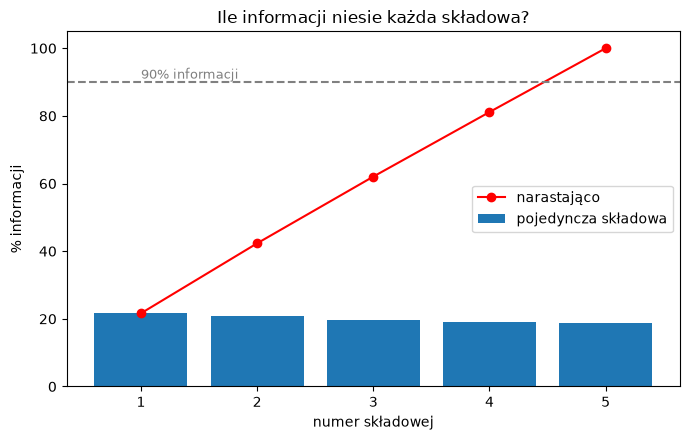

składowa 1:  21.6%   narastająco:  21.6%
składowa 2:  20.7%   narastająco:  42.3%
składowa 3:  19.7%   narastająco:  62.1%
składowa 4:  19.1%   narastająco:  81.1%
składowa 5:  18.9%   narastająco: 100.0%

Składowych potrzebnych na 90% informacji: 5 z 5


In [14]:
from sklearn.decomposition import PCA

pca_pelne = PCA().fit(X)
udzialy = pca_pelne.explained_variance_ratio_

plt.figure(figsize=(7, 4.5))
plt.bar(range(1, len(udzialy) + 1), udzialy * 100, label="pojedyncza składowa")
plt.plot(range(1, len(udzialy) + 1), np.cumsum(udzialy) * 100, "o-", color="red", label="narastająco")
plt.axhline(90, ls="--", color="gray")
plt.text(1, 91, "90% informacji", color="gray", fontsize=9)
plt.xticks(range(1, len(udzialy) + 1))
plt.xlabel("numer składowej"); plt.ylabel("% informacji")
plt.title("Ile informacji niesie każda składowa?")
plt.legend(); plt.tight_layout(); plt.show()

for i, (u, n) in enumerate(zip(udzialy, np.cumsum(udzialy)), start=1):
    print(f"składowa {i}: {u*100:5.1f}%   narastająco: {n*100:5.1f}%")
print(f"\nSkładowych potrzebnych na 90% informacji: {np.searchsorted(np.cumsum(udzialy), 0.90) + 1} z {len(udzialy)}")

Pięć niemal równych słupków - schody, nie urwisko. Każda składowa niesie mniej więcej
tyle samo informacji, a żeby zachować 90%, potrzebujemy **wszystkich pięciu**.
PCA nie ma tutaj czego ściskać.

To wyjaśnia, dlaczego nasz wykres 2D pokazywał tylko 42% informacji - i jest to już
**trzeci** sygnał mówiący to samo, obok braku łokcia.
W danych ze strukturą dwie pierwsze składowe wzięłyby zwykle 70-90%.

### 5b. Z czego zbudowane są składowe?

Składowa to nie jest żadna z oryginalnych cech - to ich **mieszanka**. Każda cecha wchodzi
do niej z pewną wagą: dodatnią albo ujemną. Zobaczmy, co dokładnie oznaczały osie
na wykresie z sekcji 5.

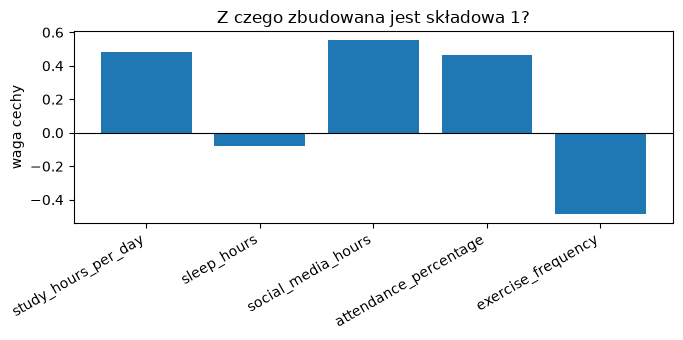

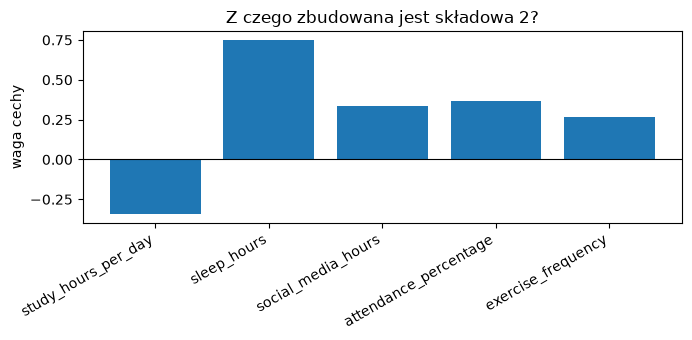

,składowa 1,składowa 2
study_hours_per_day,0.48,-0.34
sleep_hours,-0.08,0.75
social_media_hours,0.55,0.34
attendance_percentage,0.46,0.37
exercise_frequency,-0.49,0.27


In [15]:
for i in range(2):
    plt.figure(figsize=(7, 3.5))
    plt.bar(cechy, pca_pelne.components_[i])
    plt.axhline(0, color="black", lw=0.8)
    plt.xticks(rotation=30, ha="right")
    plt.ylabel("waga cechy")
    plt.title(f"Z czego zbudowana jest składowa {i + 1}?")
    plt.tight_layout(); plt.show()

wagi = pd.DataFrame(pca_pelne.components_[:2].T, index=cechy,
                    columns=["składowa 1", "składowa 2"]).round(2)
display(wagi)

**Jak to czytać:**

- **Składowa 1** - social media (+0,55), nauka (+0,48) i frekwencja (+0,46) ciągną w jedną
  stronę, a ruch (−0,49) w przeciwną. To oś "aktywność szkolno-ekranowa kontra sport":
  im bardziej w prawo na wykresie z sekcji 5, tym więcej szkoły i ekranu, a mniej ruchu.
- **Składowa 2** - to praktycznie sam sen (+0,75), reszta cech ma małe wagi.
  Im wyżej na wykresie, tym więcej snu.

Znak wagi sam w sobie nic nie znaczy (PCA mogłoby obrócić oś na odwrót) - liczy się to,
które cechy mają znaki **przeciwne**, bo to one stoją po dwóch stronach tej samej osi.

### 5c. Inna metoda spłaszczania: t-SNE

PCA działa jak cień: świeci na chmurę punktów z jednej strony i rysuje jej płaski obrys.
Zachowuje ogólny kształt, ale punkty, które były daleko od siebie „w głąb", mogą
w cieniu wylądować na sobie - widzieliśmy to przy grupach 0 i 3.

**t-SNE** pilnuje czegoś innego: żeby punkty, które w oryginalnych danych były
blisko siebie, zostały blisko także na obrazku. Nie obchodzi go natomiast, czy odległości
na mapie odpowiadają prawdziwym.

Sprawdźmy, która metoda lepiej pilnuje sąsiedztwa. Dla każdego ucznia popatrzymy
na jego 10 najbliższych sąsiadów na wykresie i policzymy, ilu z nich należy
do tej samej grupy, co on.

oryginalne 5 wymiarów: 80%
PCA 2D:                61%
t-SNE 2D:              79%


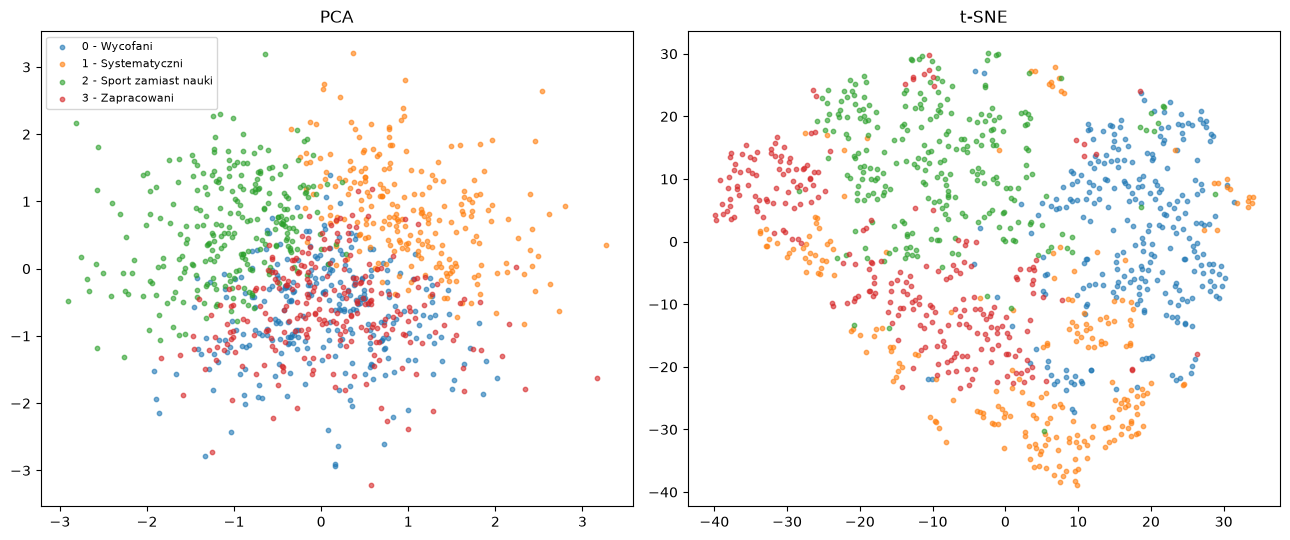

In [17]:
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

wsp_tsne = TSNE(n_components=2, random_state=0, perplexity=30).fit_transform(X)
wsp_pca = PCA(n_components=2).fit_transform(X)

def udzial_sasiadow(wspolrzedne, etykiety, k=10):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(wspolrzedne)
    sasiedzi = nn.kneighbors(wspolrzedne)[1][:, 1:]     # pomijamy sam punkt
    return (etykiety[sasiedzi] == etykiety[:, None]).mean()

g = df["grupa"].values
print(f"oryginalne 5 wymiarów: {udzial_sasiadow(X, g)*100:.0f}%")
print(f"PCA 2D:                {udzial_sasiadow(wsp_pca, g)*100:.0f}%")
print(f"t-SNE 2D:              {udzial_sasiadow(wsp_tsne, g)*100:.0f}%")

nazwy = {0: "Wycofani", 1: "Systematyczni", 2: "Sport zamiast nauki", 3: "Zapracowani"}
fig, osie = plt.subplots(1, 2, figsize=(13, 5.5))
for wspolrzedne, os_, tytul in [(wsp_pca, osie[0], "PCA"), (wsp_tsne, osie[1], "t-SNE")]:
    for nr, nazwa in nazwy.items():
        maska = df["grupa"] == nr
        os_.scatter(wspolrzedne[maska, 0], wspolrzedne[maska, 1], s=10, alpha=0.6, label=f"{nr} - {nazwa}")
    os_.set_title(tytul)
osie[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Wynik:** w oryginalnych danych sąsiad należy do tej samej grupy w 80% przypadków.
t-SNE utrzymuje 78%, a PCA tylko 61%. t-SNE naprawdę lepiej pilnuje, kto z kim sąsiaduje -
i po to właśnie się go używa.

Ale ma jedną poważną wadę. PCA mówi nam wprost, ile informacji zgubiło. **t-SNE nie podaje żadnej takiej liczby** - nie wiemy, jak bardzo zniekształcił
obraz. Zobaczmy, dlaczego to problem.

### Jedna mapa to za mało

`perplexity` to zgrubnie "ilu sąsiadów t-SNE bierze pod uwagę". Narysujmy tę samą
chmurę punktów trzy razy, zmieniając tylko ten jeden parametr.

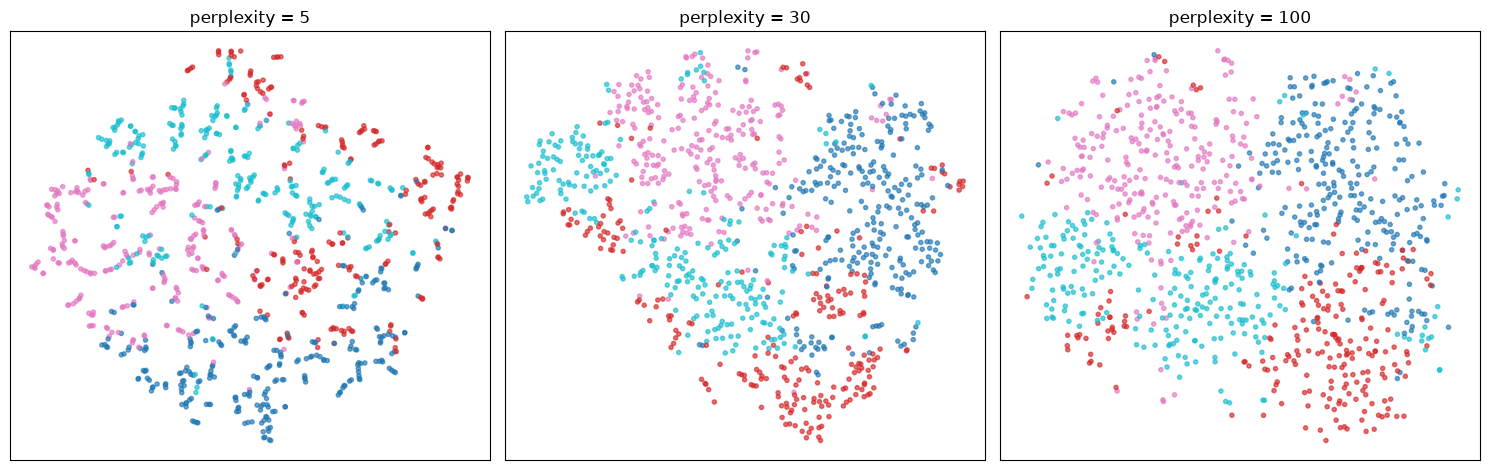

In [18]:
fig, osie = plt.subplots(1, 3, figsize=(15, 4.8))
for p, os_ in zip([5, 30, 100], osie):
    W = TSNE(n_components=2, random_state=0, perplexity=p).fit_transform(X)
    os_.scatter(W[:, 0], W[:, 1], c=df["grupa"], cmap="tab10", s=9, alpha=0.65)
    os_.set_title(f"perplexity = {p}")
    os_.set_xticks([]); os_.set_yticks([])
plt.tight_layout(); plt.show()

**To są te same dane na wszystkich trzech wykresach.**

- `perplexity = 5` - kilkadziesiąt osobnych wysepek i nitek. Wygląda jak dane
  o bardzo bogatej strukturze.
- `perplexity = 30` - jedna pofałdowana chmura.
- `perplexity = 100` - gładka plama.

Wysepki po lewej są wytworem rysowania, a nie własnością danych.

**Zasada do zapamiętania:** jeśli obrazek zmienia swoją historię, gdy przestawisz
jeden parametr, to ta historia nie pochodzi z danych. Na wykresie t-SNE wolno sprawdzać,
czy coś się wyraźnie oddziela - ale nie wolno z niego odczytywać, ile jest grup
ani jak bardzo się różnią. 

## 6. Czy te grupy są do czegoś przydatne?

Wiemy już, że naturalnych grup w tych danych nie ma. Ale podział na cztery obszary
istnieje i ma nazwy. Pytanie brzmi: czy te obszary różnią się w czymś, na czym nam zależy?

Mamy do tego idealne narzędzie. W naszym zbiorze jest kolumna `exam_score` -
wynik egzaminu - której **model nigdy nie widział**. Do grupowania użyliśmy wyłącznie
nawyków. Jeśli grupy różnią się wynikami, to znaczy, że podział na nawyki
mówi coś o efektach nauki.

,nazwa,liczebnosc,sredni_wynik,odchylenie
grupa,,,,
0,Wycofani,269,67.0,16.1
1,Systematyczni,228,70.7,16.4
2,Sport zamiast nauki,258,61.8,15.3
3,Zapracowani,245,79.7,14.5


Różnica między najlepszą a najgorszą grupą: 17.9 punktu


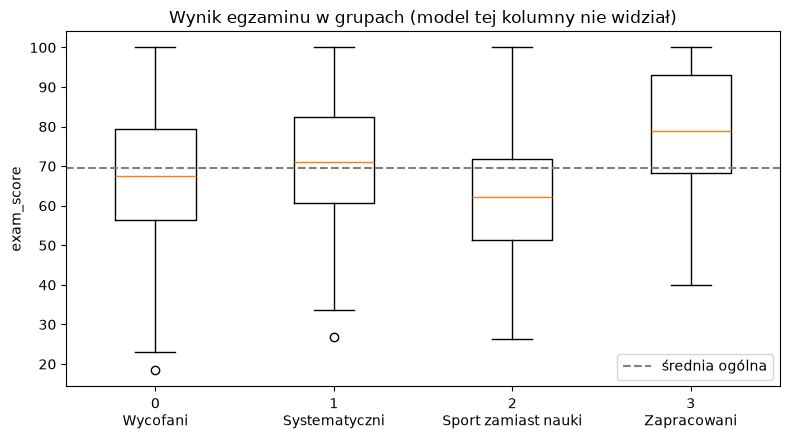

In [19]:
podsumowanie = df.groupby("grupa").agg(
    liczebnosc=("exam_score", "size"),
    sredni_wynik=("exam_score", "mean"),
    odchylenie=("exam_score", "std"),
).round(1)
podsumowanie.insert(0, "nazwa", [nazwy[g] for g in podsumowanie.index])
display(podsumowanie)

rozpietosc = podsumowanie["sredni_wynik"].max() - podsumowanie["sredni_wynik"].min()
print(f"Różnica między najlepszą a najgorszą grupą: {rozpietosc:.1f} punktu")

plt.figure(figsize=(8, 4.5))
plt.boxplot([df.loc[df["grupa"] == g, "exam_score"] for g in sorted(nazwy)])
plt.xticks(range(1, len(nazwy) + 1), [f"{g}\n{nazwy[g]}" for g in sorted(nazwy)])
plt.axhline(df["exam_score"].mean(), ls="--", color="gray", label="średnia ogólna")
plt.ylabel("exam_score")
plt.title("Wynik egzaminu w grupach (model tej kolumny nie widział)")
plt.legend(); plt.tight_layout(); plt.show()

**Tak - i to wyraźnie.** „Zapracowani" mają średnio **79,7** punktu, a „Sport zamiast nauki"
**61,8**. To różnica **17,9 punktu**, wyciągnięta wyłącznie z nawyków, bez zaglądania
do wyników. Podział, który nie odkrył żadnych naturalnych typów uczniów, okazuje się
użyteczny w praktyce - dokładnie tak działa segmentacja klientów w firmach.

Dwie uczciwe uwagi na koniec:

- **Pudełka mocno na siebie zachodzą.** Odchylenie wyniku wewnątrz grup to 14-16 punktów,
  przy 16,9 w całym zbiorze. Grupa mówi coś o **średniej**, a nic o konkretnym uczniu -
  w „Sport zamiast nauki" są uczniowie z wynikiem 100, a wśród „Zapracowanych" z wynikiem 40.
- **Skąd ta różnica?** Głównie z jednej cechy: `study_hours_per_day` koreluje z `exam_score`
  na poziomie 0,83. Grupy różniące się liczbą godzin nauki muszą różnić się wynikami.
  k-means tego nie wiedział - po prostu znalazł obszary, które przy okazji się tym różnią.

## Podsumowanie

- **Uczenie nienadzorowane** szuka struktury w danych **bez etykiet**.
- **k-means** dzieli dane na `k` grup wokół środków. Przed grupowaniem **standaryzujemy** cechy,
  bo algorytm mierzy odległości.
- **k-means zawsze zwróci `k` grup** - nawet gdy żadnych grup nie ma. Dlatego trzeba sprawdzać,
  czy wynik cokolwiek znaczy: macierzą korelacji, metodą łokcia, rozkładem składowych PCA.
- W naszych danych **naturalnych grup nie było**. Mimo to podział na 4 obszary okazał się
  użyteczny: grupy różnią się o 17,9 punktu w wyniku egzaminu.
- **PCA i t-SNE** pozwalają zobaczyć dane wielowymiarowe na płasko, ale każdy obrazek
  coś zniekształca. PCA mówi ile (42%), t-SNE nie mówi nic.



**Praca własna:** te same narzędzia zastosujecie samodzielnie na danych o **sprzedaży gier wideo**. 